# Hands-On: Facies Classification from Well Logs
**AI in Oil & Gas · Follow-up notebook to the lecture *Well Log Analysis and Lithology/Facies Classification***

In the lecture we went **physics → engineering → AI**. Here you build the AI part yourself, on public data, in about 45 minutes.

**What you will do**

| Step | What | Lecture slide |
|---|---|---|
| 1 | Load the logs and learn what each curve means | 5–6 |
| 2 | Look at the class mix (rare facies!) | 13 |
| 3 | Prepare features (neighbour-depth context) | 10 |
| 4 | Train a baseline model and test it **by well** | 11–13 |
| 5 | Show why a random split gives a *fake* score | 13 |
| 6 | Judge the model: per-class scores, confusion matrix, adjacent-facies accuracy | 13 |
| 7 | Geology sanity check (does the facies flicker?) | 13 |
| 8 | Flag low-confidence intervals for expert review | 15 |
| 9 | Optional: no labels? Cluster into electrofacies | 11 |

**Data:** public well-log dataset from the 2016 SEG machine-learning contest (Hugoton and Panoma gas fields, Kansas, USA). It has 3,232 depth samples from 8 wells, labelled with 9 facies from core description. Reference: B. Hall (2016), *Facies classification using machine learning*, The Leading Edge 35(10), 906-909.

> Remember the lecture: the labels come from a geologist's description of core, so they carry opinion. Do not expect 100%.

**Run it in Google Colab:** *Runtime → Run all*. No GPU needed.

## 1. Setup and load the data

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import LeaveOneGroupOut, KFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

URL = "https://raw.githubusercontent.com/seg/2016-ml-contest/master/training_data.csv"
df = pd.read_csv(URL)
df = df.rename(columns={"Well Name": "Well"})
print(df.shape)
df.head()

(3232, 11)


,Facies,Formation,Well,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
0,3,A1 SH,SHRIMPLIN,2793.0,77.45,0.664,9.9,11.915,4.6,1,1.000
1,3,A1 SH,SHRIMPLIN,2793.5,78.26,0.661,14.2,12.565,4.1,1,0.979
2,3,A1 SH,SHRIMPLIN,2794.0,79.05,0.658,14.8,13.050,3.6,1,0.957
3,3,A1 SH,SHRIMPLIN,2794.5,86.10,0.655,13.9,13.115,3.5,1,0.936
4,3,A1 SH,SHRIMPLIN,2795.0,74.58,0.647,13.5,13.300,3.4,1,0.915


### What each column means (the physics, from slides 5-6)

| Column | Curve | What it senses |
|---|---|---|
| `GR` | Gamma ray | Natural radioactivity. High often means shale |
| `ILD_log10` | Deep resistivity (log10) | Resistance to current. Fluid and tightness |
| `DeltaPHI` | Neutron-density porosity difference | Separation of the two porosity curves. Clay and gas effect |
| `PHIND` | Average neutron-density porosity | Overall porosity |
| `PE` | Photoelectric factor | Mineral (quartz ~1.8, calcite ~5.1, dolomite ~3.1) |
| `NM_M` | Non-marine / marine flag | 1 = non-marine, 2 = marine (from geologist) |
| `RELPOS` | Relative position | 0-1 position inside the marine/non-marine unit |

`Facies` is our **target**. `Depth` and `Formation` help us understand the data, but we will **not** use them as inputs (they would make the model memorise places, not rocks).

In [2]:
FACIES = {1: "SS  Nonmarine sandstone", 2: "CSiS Nonmarine coarse siltstone", 3: "FSiS Nonmarine fine siltstone",
          4: "SiSh Marine siltstone & shale", 5: "MS  Mudstone", 6: "WS  Wackestone",
          7: "D   Dolomite", 8: "PS  Packstone-grainstone", 9: "BS  Phylloid-algal bafflestone"}
SHORT = {k: v.split()[0] for k, v in FACIES.items()}
COLORS = ["#F2D16B", "#E7A93C", "#C8553D", "#8A9BB0", "#5B6B7C", "#3E6A8F", "#6B4E9B", "#1F8A70", "#0B1F3A"]
CMAP = ListedColormap(COLORS)

CURVES = ["GR", "ILD_log10", "DeltaPHI", "PHIND", "PE"]
print("Wells and samples:"); print(df["Well"].value_counts().to_string())
print("\nMissing values per column:"); print(df.isna().sum().to_string())

Wells and samples:
Well
CROSS H CATTLE     501
SHRIMPLIN          471
NEWBY              463
LUKE G U           461
SHANKLE            449
NOLAN              415
CHURCHMAN BIBLE    404
Recruit F9          68

Missing values per column:
Facies       0
Formation    0
Well         0
Depth        0
GR           0
ILD_log10    0
DeltaPHI     0
PHIND        0
PE           0
NM_M         0
RELPOS       0


## 2. Know your data: class balance (slide 13, pitfall 2)
Before any model, count the facies. **Rare classes are easy to ignore** and overall accuracy hides that.

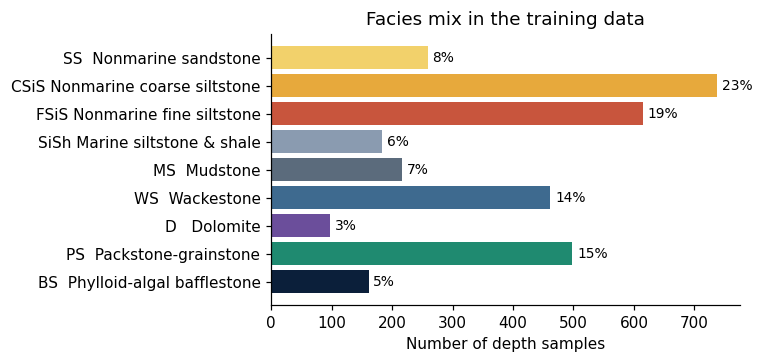

In [3]:
counts = df["Facies"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh([FACIES[i] for i in counts.index], counts.values, color=[COLORS[i-1] for i in counts.index])
ax.invert_yaxis(); ax.set_xlabel("Number of depth samples")
for y, v in enumerate(counts.values): ax.text(v + 8, y, f"{v/len(df):.0%}", va="center", fontsize=9)
ax.set_title("Facies mix in the training data"); plt.tight_layout(); plt.show()

## 3. Look at a well like a petrophysicist
A log display: curves on the left, facies as a colour strip on the right. Spend a minute here. Can you *see* the patterns that the model has to learn?

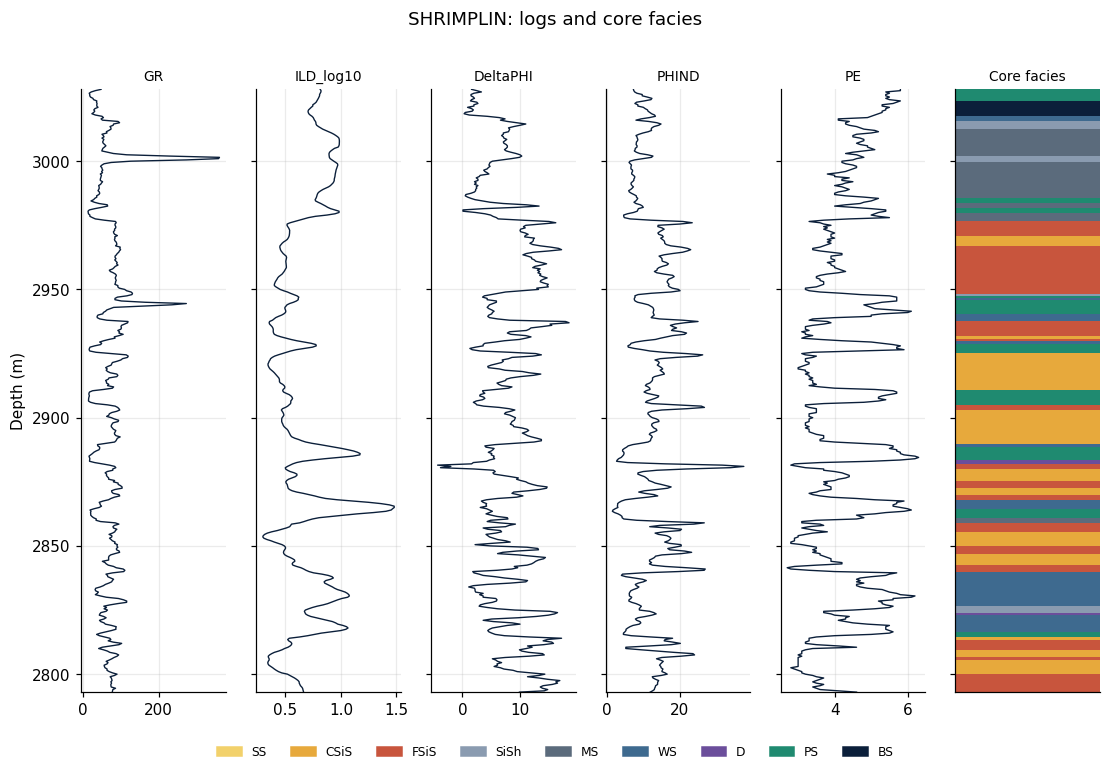

In [4]:
def log_display(well_df, title, pred=None):
    ncols = len(CURVES) + 1 + (1 if pred is not None else 0)
    fig, axes = plt.subplots(1, ncols, figsize=(1.7 * ncols, 7), sharey=True)
    z = well_df["Depth"].values
    for ax, c in zip(axes, CURVES):
        ax.plot(well_df[c].values, z, color="#0B1F3A", lw=0.9)
        ax.set_title(c, fontsize=9); ax.grid(alpha=0.25)
    def strip(ax, labels, name):
        img = np.repeat(labels.reshape(-1, 1), 2, axis=1)
        ax.imshow(img, aspect="auto", cmap=CMAP, vmin=1, vmax=9,
                  extent=[0, 1, z.max(), z.min()], interpolation="nearest")
        ax.set_xticks([]); ax.set_title(name, fontsize=9)
    strip(axes[len(CURVES)], well_df["Facies"].values, "Core facies")
    if pred is not None: strip(axes[len(CURVES) + 1], pred, "Predicted")
    axes[0].set_ylabel("Depth (m)"); axes[0].invert_yaxis()
    handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[i-1]) for i in FACIES]
    fig.legend(handles, [SHORT[i] for i in FACIES], ncol=9, loc="lower center", fontsize=8, frameon=False)
    fig.suptitle(title); fig.tight_layout(rect=[0, 0.04, 1, 0.97]); plt.show()

log_display(df[df.Well == "SHRIMPLIN"].sort_values("Depth"), "SHRIMPLIN: logs and core facies")

## 4. The fingerprint (slide 6)
No single curve decides. But each facies has a *typical* value on each curve. Compare the median per facies:

,GR,ILD_log10,DeltaPHI,PHIND,PE
SS Nonmarine sandstone,61.970000,0.350000,3.500000,15.150000,2.880000
CSiS Nonmarine coarse siltstone,72.190000,0.560000,5.470000,13.350000,3.200000
FSiS Nonmarine fine siltstone,78.510000,0.540000,5.700000,18.350000,3.200000
SiSh Marine siltstone & shale,76.110000,0.770000,5.270000,10.970000,3.720000
MS Mudstone,51.470000,0.890000,3.480000,8.040000,4.040000
WS Wackestone,47.870000,0.910000,2.400000,7.000000,4.200000
D Dolomite,42.660000,0.440000,5.710000,13.050000,3.650000
PS Packstone-grainstone,34.980000,0.780000,1.500000,8.720000,4.560000
BS Phylloid-algal bafflestone,39.220000,0.600000,0.990000,13.230000,5.200000


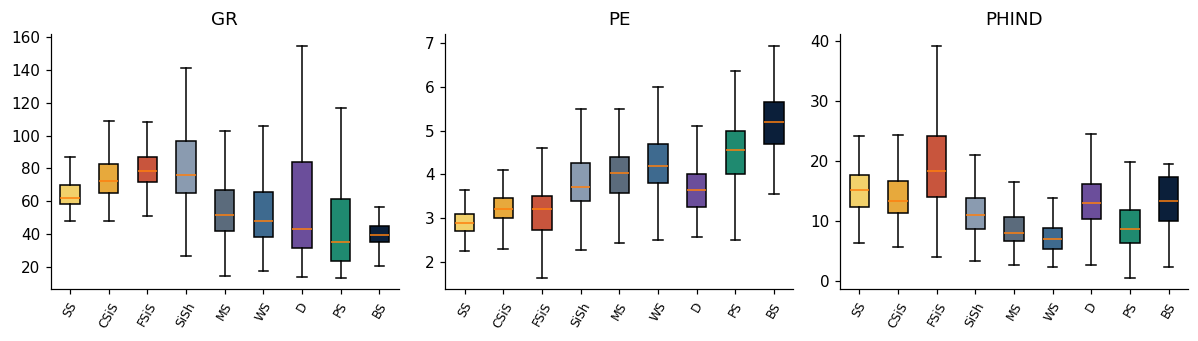

In [5]:
fp = df.groupby("Facies")[CURVES].median().round(2)
fp.index = [FACIES[i] for i in fp.index]
display(fp.style.background_gradient(cmap="Blues", axis=0))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, c in zip(axes, ["GR", "PE", "PHIND"]):
    data = [df.loc[df.Facies == k, c] for k in FACIES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    for patch, col in zip(bp["boxes"], COLORS): patch.set_facecolor(col)
    ax.set_xticks(range(1, 10)); ax.set_xticklabels([SHORT[k] for k in FACIES])
    ax.set_title(c); ax.tick_params(axis="x", rotation=60, labelsize=8)
plt.tight_layout(); plt.show()

**Look for:** the boxes overlap a lot. That is exactly why one curve is not enough, and why we use **many curves together**.

## 5. Prepare features (slide 10)
Rock at one depth is related to the rock just above and below. We add **neighbour-depth features** *inside each well* (never across wells):
- the value 1 and 2 samples above and below,
- a 5-sample rolling mean (a smooth version of the curve).

We use only log curves as features, not labels, so this does not leak the answer.

In [6]:
df = df.sort_values(["Well", "Depth"]).reset_index(drop=True)

def add_context(d, cols, shifts=(1, 2), win=5):
    out = d.copy()
    g = out.groupby("Well")
    for c in cols:
        for s in shifts:
            out[f"{c}_up{s}"] = g[c].shift(s)
            out[f"{c}_dn{s}"] = g[c].shift(-s)
        out[f"{c}_mean{win}"] = g[c].transform(lambda x: x.rolling(win, center=True, min_periods=1).mean())
    ctx = [c for c in out.columns if any(t in c for t in ("_up", "_dn", "_mean"))]
    out[ctx] = out.groupby("Well")[ctx].transform(lambda x: x.ffill().bfill())   # fill well edges
    return out

dfx = add_context(df, CURVES)
BASE = CURVES + ["NM_M", "RELPOS"]
CTX = [c for c in dfx.columns if any(t in c for t in ("_up", "_dn", "_mean"))]
print(len(BASE), "base features;", len(CTX), "context features")

y = dfx["Facies"].values
groups = dfx["Well"].values

7 base features; 25 context features


## 6. The honest test: hold out whole wells (slide 13, pitfall 1)
Two ways to split the data:

* **Random split** (wrong): neighbouring depths from the *same well* land in both train and test. They look almost identical, so the score is inflated.
* **Leave-one-well-out** (right): train on 7 wells, test on the 8th, repeat. This mimics the real job: *predict a well the model has never seen*.

In [7]:
def adjacent_accuracy(y_true, y_pred):
    # Facies that are geologically close (from the SEG contest definition)
    adj = {1: [2], 2: [1, 3], 3: [2], 4: [5], 5: [4, 6], 6: [5, 7, 8], 7: [6, 8], 8: [6, 7, 9], 9: [7, 8]}
    ok = [(t == p) or (p in adj[t]) for t, p in zip(y_true, y_pred)]
    return float(np.mean(ok))

def make_rf():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=SEED)

X0 = dfx[BASE].values
# 1) WRONG: random 5-fold split
p_random = cross_val_predict(make_rf(), X0, y, cv=KFold(5, shuffle=True, random_state=SEED))
# 2) RIGHT: leave one well out
p_well = cross_val_predict(make_rf(), X0, y, cv=LeaveOneGroupOut(), groups=groups)

res = pd.DataFrame({"Split": ["Random split (leaky)", "Leave-one-well-out (honest)"],
                    "Accuracy": [accuracy_score(y, p_random), accuracy_score(y, p_well)],
                    "Macro F1": [f1_score(y, p_random, average="macro"), f1_score(y, p_well, average="macro")]}).round(3)
display(res)

,Split,Accuracy,Macro F1
0,Random split (leaky),0.716,0.712
1,Leave-one-well-out (honest),0.511,0.456


**Discussion:** the random split looks much better. That gap is the *depth leakage* from the lecture. Only the second number tells you how the model will behave on a new well.

## 7. Does context help? Compare feature sets and models
All scores below use leave-one-well-out. Start simple (slide 12): a random forest is our baseline.

In [8]:
Xc = dfx[BASE + CTX].values
runs = {}
runs["RF: base curves"] = p_well
runs["RF: + neighbour context"] = cross_val_predict(make_rf(), Xc, y, cv=LeaveOneGroupOut(), groups=groups)
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, class_weight="balanced", random_state=SEED)
runs["Gradient boosting: + context"] = cross_val_predict(hgb, Xc, y, cv=LeaveOneGroupOut(), groups=groups)

tbl = pd.DataFrame({k: {"Accuracy": accuracy_score(y, p), "Macro F1": f1_score(y, p, average="macro"),
                        "Adjacent-facies acc.": adjacent_accuracy(y, p)} for k, p in runs.items()}).T.round(3)
display(tbl)

,Accuracy,Macro F1,Adjacent-facies acc.
RF: base curves,0.511,0.456,0.900
RF: + neighbour context,0.505,0.441,0.899
Gradient boosting: + context,0.512,0.464,0.899


Notice the third column. **Adjacent-facies accuracy** counts a miss between geologically similar facies as less serious. It is usually much higher than plain accuracy.

## 8. Look inside the errors (slide 13, pitfalls 2 and 3)

Best model by macro F1: Gradient boosting: + context 

              precision    recall  f1-score   support

          SS       0.33      0.18      0.23       259
        CSiS       0.50      0.62      0.55       738
        FSiS       0.60      0.56      0.58       615
        SiSh       0.54      0.53      0.54       184
          MS       0.28      0.16      0.20       217
          WS       0.47      0.55      0.50       462
           D       0.44      0.31      0.36        98
          PS       0.55      0.55      0.55       498
          BS       0.58      0.75      0.66       161

    accuracy                           0.51      3232
   macro avg       0.48      0.47      0.46      3232
weighted avg       0.50      0.51      0.50      3232



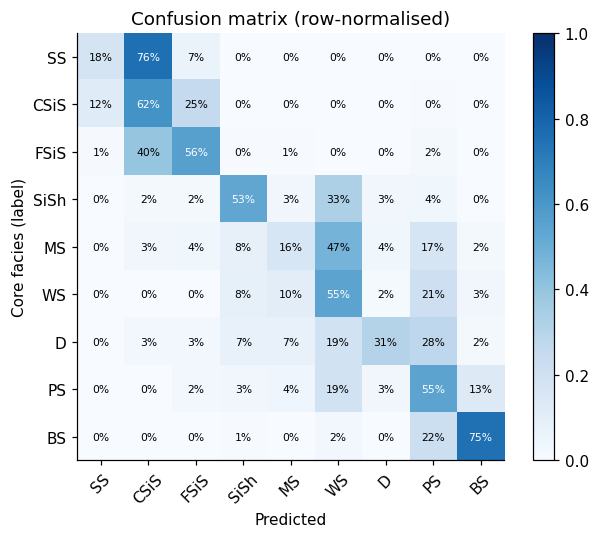

In [9]:
best_name = tbl["Macro F1"].idxmax()
pred = runs[best_name]
print("Best model by macro F1:", best_name, "\n")
print(classification_report(y, pred, target_names=[SHORT[i] for i in FACIES], digits=2))

cm = confusion_matrix(y, pred, labels=list(FACIES))
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(9)); ax.set_xticklabels([SHORT[i] for i in FACIES], rotation=45)
ax.set_yticks(range(9)); ax.set_yticklabels([SHORT[i] for i in FACIES])
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{cmn[i, j]:.0%}", ha="center", va="center", fontsize=7,
                color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Core facies (label)")
ax.set_title("Confusion matrix (row-normalised)"); plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

**Read it like a geologist.** Which facies are confused with each other? Are they neighbours in the adjacent-facies list? Which rare facies does the model struggle with?

### Per-well scores
A model can do well on some wells and badly on others (different tools, different geology). Treat the small well (`Recruit F9`, only 68 samples) with caution: a high score on very few samples proves little.

In [10]:
pw = pd.DataFrame({"Well": groups, "ok": (pred == y)}).groupby("Well")["ok"].agg(["mean", "size"])
pw.columns = ["Accuracy", "Samples"]; display(pw.round(3).sort_values("Accuracy"))

,Accuracy,Samples
Well,,
CROSS H CATTLE,0.397,501
NOLAN,0.460,415
NEWBY,0.467,463
SHANKLE,0.468,449
CHURCHMAN BIBLE,0.507,404
SHRIMPLIN,0.614,471
LUKE G U,0.620,461
Recruit F9,0.853,68


## 9. Visual check on a blind well

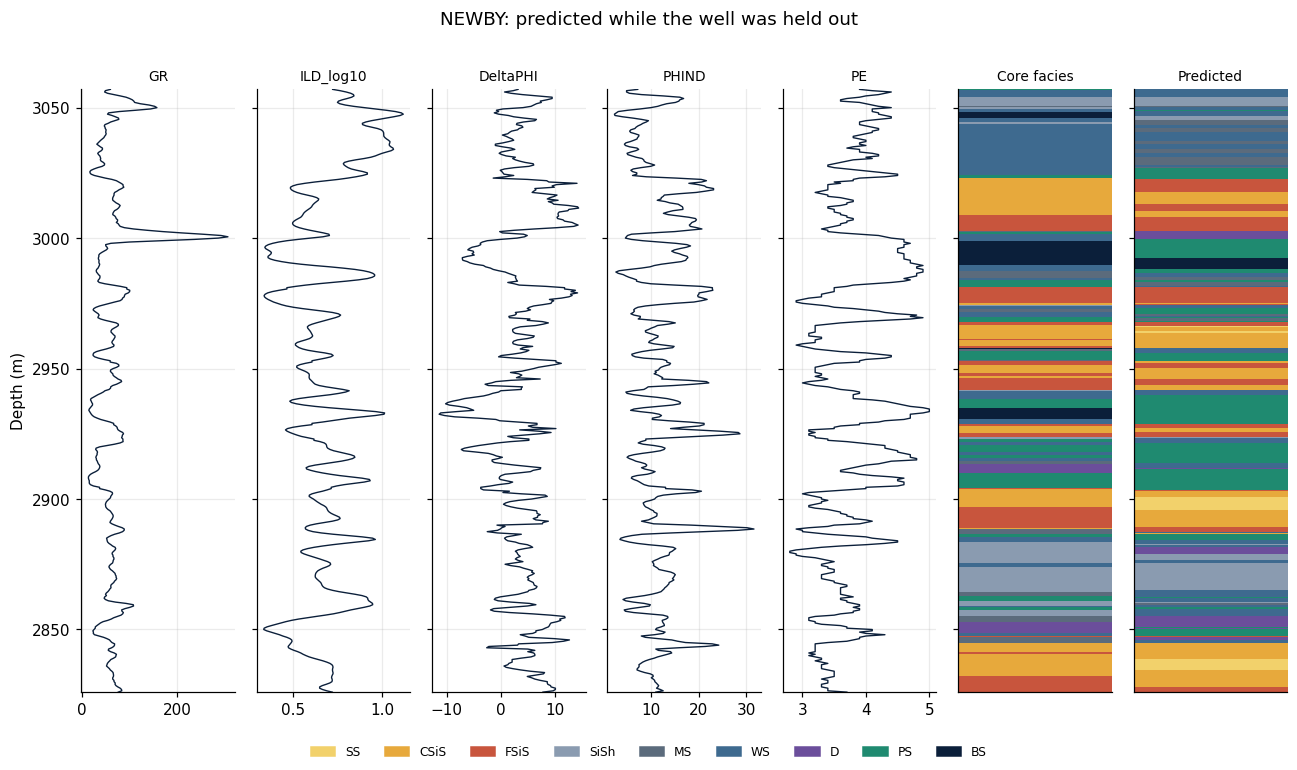

In [11]:
well = "NEWBY"
m = (dfx.Well == well).values
log_display(dfx[m], f"{well}: predicted while the well was held out", pred=pred[m])

## 10. Geology sanity check (slide 13, last point)
*Real rock does not flicker.* Count how often the facies label changes from one sample to the next, and try a small smoothing filter on the predictions.

In [12]:
def smooth_mode(labels, wells, win=5):
    out = labels.copy()
    for w in np.unique(wells):
        idx = np.where(wells == w)[0]
        s = pd.Series(labels[idx])
        out[idx] = s.rolling(win, center=True, min_periods=1).apply(lambda v: pd.Series(v).mode().iloc[0]).astype(int).values
    return out

def flips_per_100(labels, wells):
    n = 0
    for w in np.unique(wells):
        l = labels[wells == w]; n += (np.diff(l) != 0).sum()
    return 100 * n / len(labels)

smooth = smooth_mode(pred, groups, win=5)
chk = pd.DataFrame({"Flips per 100 samples": [flips_per_100(y, groups), flips_per_100(pred, groups), flips_per_100(smooth, groups)],
                    "Accuracy": [1.0, accuracy_score(y, pred), accuracy_score(y, smooth)],
                    "Adjacent-facies acc.": [1.0, adjacent_accuracy(y, pred), adjacent_accuracy(y, smooth)]},
                   index=["Core (truth)", "Model", "Model + 5-sample smoothing"]).round(3)
display(chk)

,Flips per 100 samples,Accuracy,Adjacent-facies acc.
Core (truth),15.254,1.000,1.000
Model,21.380,0.512,0.899
Model + 5-sample smoothing,12.376,0.516,0.895


If the model flips far more often than the core description, the output is *noisy*, even if the accuracy looks fine. Smoothing is a cheap fix, but it can also erase thin real beds. This is a judgement call for the geologist.

## 11. Human in the loop: flag low-confidence intervals (slide 15)
Instead of trusting every prediction, we ask the model *how sure it is* and send the unsure intervals to the geologist first.

In [13]:
# Out-of-fold probabilities (still leave-one-well-out)
rf = make_rf()
proba = cross_val_predict(rf, Xc, y, cv=LeaveOneGroupOut(), groups=groups, method="predict_proba")
classes = np.array(sorted(FACIES))
p_hat = classes[proba.argmax(axis=1)]
conf = proba.max(axis=1)

rows = []
for thr in [0.4, 0.5, 0.6, 0.7]:
    keep = conf >= thr
    rows.append({"Confidence threshold": thr, "Share auto-accepted": keep.mean(),
                 "Accuracy on accepted": accuracy_score(y[keep], p_hat[keep]),
                 "Accuracy on flagged for review": accuracy_score(y[~keep], p_hat[~keep]) if (~keep).any() else np.nan})
display(pd.DataFrame(rows).round(3))

,Confidence threshold,Share auto-accepted,Accuracy on accepted,Accuracy on flagged for review
0,0.4,0.814,0.543,0.342
1,0.5,0.573,0.570,0.418
2,0.6,0.341,0.586,0.463
3,0.7,0.188,0.569,0.490


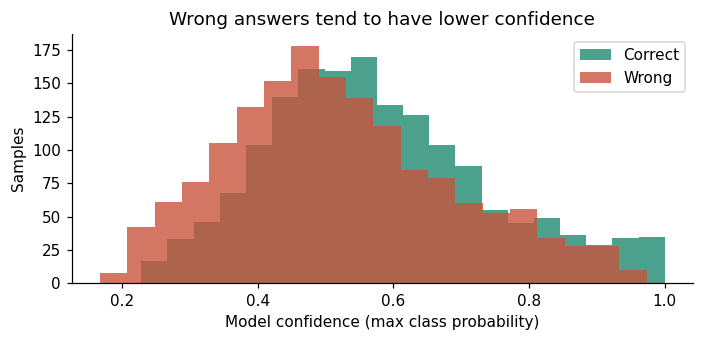

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(conf[p_hat == y], bins=20, alpha=0.8, label="Correct", color="#1F8A70")
ax.hist(conf[p_hat != y], bins=20, alpha=0.8, label="Wrong", color="#C8553D")
ax.set_xlabel("Model confidence (max class probability)"); ax.set_ylabel("Samples"); ax.legend()
ax.set_title("Wrong answers tend to have lower confidence"); plt.tight_layout(); plt.show()

**Takeaway:** the model's confidence is a useful *triage signal*. The geologist reviews the flagged part first; fixes go back as new labels, and we retrain.

## 12. Which curves matter? (explainability)
One reason to start with tree models (slide 12): they give a quick answer to *why*.

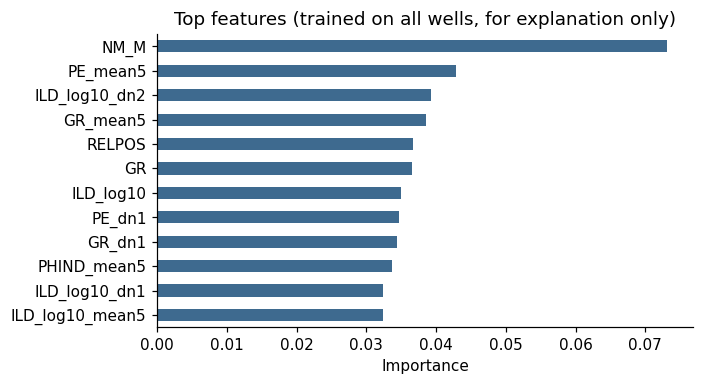

In [15]:
rf_full = make_rf().fit(Xc, y)
imp = pd.Series(rf_full.feature_importances_, index=BASE + CTX).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
imp[::-1].plot.barh(ax=ax, color="#3E6A8F"); ax.set_xlabel("Importance")
ax.set_title("Top features (trained on all wells, for explanation only)"); plt.tight_layout(); plt.show()

Does it match the physics? Compare with slides 5-6. If a feature such as `NM_M` or `RELPOS` dominates, ask yourself: is the model reading *rock*, or reading *geologist-provided context*?

## 13. Optional: no labels? Cluster into electrofacies (slide 11)
Pretend we have **no core labels**. We let K-means group similar samples. A geologist would then name each group.

In [16]:
Xs = StandardScaler().fit_transform(dfx[CURVES].values)
km = KMeans(n_clusters=6, n_init=10, random_state=SEED).fit(Xs)
dfx["Electrofacies"] = km.labels_ + 1
print("Agreement with core facies (adjusted Rand index):", round(adjusted_rand_score(y, km.labels_), 3), "(0 = random, 1 = identical)")
print("\nMedian curve values per electrofacies:")
display(dfx.groupby("Electrofacies")[CURVES].median().round(2))
display(pd.crosstab(dfx["Electrofacies"], dfx["Facies"].map(SHORT)))

Agreement with core facies (adjusted Rand index): 0.188 (0 = random, 1 = identical)

Median curve values per electrofacies:


,GR,ILD_log10,DeltaPHI,PHIND,PE
Electrofacies,,,,,
1,78.05,0.56,-7.00,31.44,2.50
2,37.72,0.50,1.50,12.66,5.10
3,68.42,0.46,3.58,15.98,3.00
4,44.73,0.91,2.00,7.00,4.30
5,174.46,0.85,4.66,8.28,4.17
6,76.91,0.60,8.60,13.05,3.46


Facies,BS,CSiS,D,FSiS,MS,PS,SS,SiSh,WS
Electrofacies,,,,,,,,,
1,0,53,3,145,7,6,2,1,0
2,116,1,16,6,6,129,0,2,30
3,1,306,36,167,16,24,224,16,18
4,38,38,10,19,151,293,10,46,362
5,6,0,10,1,11,13,0,29,8
6,0,340,23,277,26,33,23,90,44


Clusters are **not** the same as core facies, and that is fine. They are a fast *first look*. Supervised models need labels; clustering does not.

## 14. Your turn (exercises)

1. **Normalise per well.** Subtract each well's median and divide by its spread for each curve. Does leave-one-well-out accuracy improve? (Tools differ between wells.)
2. **Wider context.** Change `shifts=(1, 2)` to `(1, 2, 3, 4)` and `win=5` to `11`. When does more context stop helping?
3. **Drop the geologist's hints.** Remove `NM_M` and `RELPOS` from `BASE`. How much does the score fall? What does that tell you about the model?
4. **Class weights.** Remove `class_weight`. Which facies get worse first?
5. **Deep learning.** Build a 1D-CNN (or LSTM) on windows of the curves. Beat the baseline *with leave-one-well-out testing*, and explain *why* it did or did not.
6. **Plausibility.** Add a rule that removes facies intervals thinner than N samples. Is the result more geological?

## Wrap-up
- Logs are indirect; the **combination** of curves is the fingerprint.
- **Test by well**, never by random depth.
- Look at **each class**, the confusion matrix, and **adjacent-facies** accuracy, not only overall accuracy.
- Do the **geology sanity check**.
- Use confidence to put the **expert in the loop**. AI supports the expert; it does not replace them.

*Data: SEG 2016 ML contest facies dataset (public). Figures and scores will differ slightly with library versions.*